In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [3]:
final_data = pd.read_csv("../data/fingers_crossed.csv")

final_data.replace(2.0, 1.0, inplace=True)

final_data.head()

#final_data[final_data["final_result"] == 2.0]



,Unnamed: 0,scoreCA,final_result,region,highest_education,imd_band,age_band,studied_credits,disability_N,disability_Y,...,ouelluminate,ouwiki,page,questionnaire,quiz,repeatactivity,resource,sharedsubpage,subpage,url
0,0,82.4,1.0,East Anglian Region,3.0,10.0,0.0,240,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,13.0,0.0,32.0,5.0
1,1,65.4,1.0,Scotland,3.0,3.0,1.0,60,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,12.0,0.0,87.0,48.0
2,1,76.3,1.0,South East Region,1.0,6.0,1.0,60,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,19.0,0.0,144.0,90.0
3,3,55.0,1.0,West Midlands Region,1.0,6.0,1.0,60,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,45.0,0.0,79.0,14.0
4,4,66.9,1.0,Wales,1.0,9.0,1.0,60,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,11.0,0.0,91.0,45.0


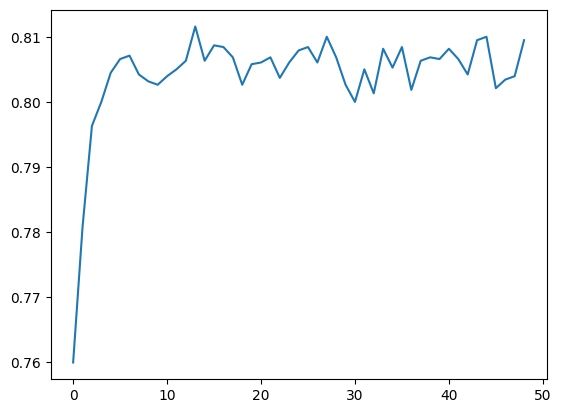

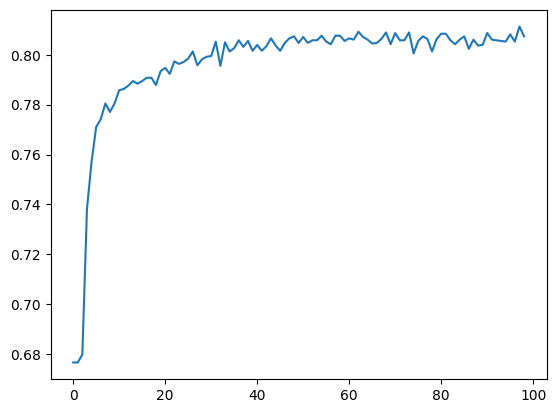

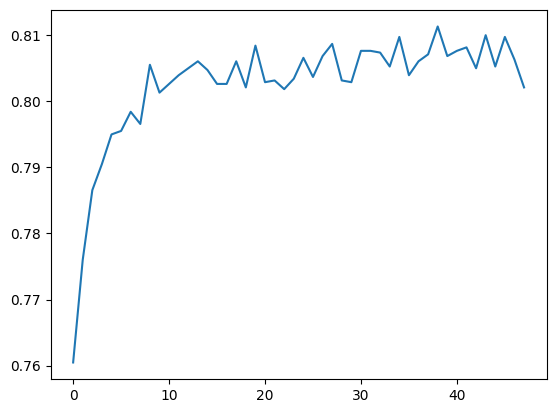

In [76]:
score_list_depth = []
for i in range(1, 50):
    clf = HistGradientBoostingClassifier(max_depth=i).fit(X_train, y_train)
    score_list_depth.append(clf.score(X_val, y_val))

plt.plot(score_list_depth)
plt.show()

score_list_iter = []
for i in range(1, 100):
    clf = HistGradientBoostingClassifier(max_iter=i).fit(X_train, y_train)
    score_list_iter.append(clf.score(X_val, y_val))

plt.plot(score_list_iter)
plt.show()

score_list_leaf = []
for i in range(2, 50):
    clf = HistGradientBoostingClassifier(max_leaf_nodes=i).fit(X_train, y_train)
    score_list_leaf.append(clf.score(X_val, y_val))

plt.plot(score_list_leaf)
plt.show()

ac: 0.8136363636363636  p: 0.8067331083785025  r: 0.7461541340180664  f1: 0.7645161874578632


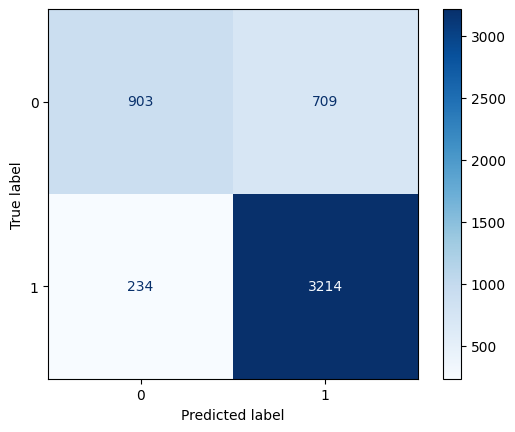

In [5]:
X = final_data.iloc[:,4:]
y = final_data["final_result"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, random_state=0)


#X.info()
clf = HistGradientBoostingClassifier().fit(X_train, y_train)
#clf.score(X_test, y_test)
y_test_p = clf.predict(X_test)

a = accuracy_score(y_test, y_test_p)#, average="macro")
f1 = f1_score(y_test, y_test_p, average="macro")
p = precision_score(y_test, y_test_p, average="macro")
r = recall_score(y_test, y_test_p, average="macro")
#classification_report, 
cm = confusion_matrix(y_test, y_test_p)
print("ac:", a, " p:", p, " r:", r, " f1:", f1)

ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.savefig("../results/figures/boostingConfusionMatrix.png")
plt.show()